# Nexo Lab · Del dato a la mirada
## Análisis, entrenamiento y reconocimiento de objetos
**Proyecto Significativo 3 · Lorena Abigail Coca Ccorpa · SENATI**

Integra las semanas 9–12: análisis de datos y Machine Learning, Git/GitHub, OpenCV, cámara y desarrollo web. Los datasets y las imágenes de ejemplo están incluidos en el repositorio. Ejecuta todas las celdas en orden.

**Tres tareas distintas:** entrenar una regresión de costos con datos sintéticos; entrenar un clasificador con imágenes Digits reales incluidas; ejecutar una red MobileNetV2 ya entrenada por sus autores. No atribuimos el entrenamiento de ImageNet al proyecto.

In [1]:
from pathlib import Path
import sys, time
root = Path.cwd() if (Path.cwd()/"app.py").exists() else Path.cwd().parent
sys.path.insert(0, str(root))
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage
import io
from PIL import Image
import cv2
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, confusion_matrix, classification_report
from app import digit_features
from object_model import classify_object, catalog
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.prop_cycle':plt.cycler(color=['#d65b31','#3554bb','#698572'])})
print('Datos locales:', sorted(p.name for p in (root/'data').glob('*.csv')))

def show(fig):
    buffer=io.BytesIO()
    fig.savefig(buffer,format="jpeg",dpi=90,bbox_inches="tight",pil_kwargs={"quality":80,"optimize":True})
    display(DisplayImage(data=buffer.getvalue()))
    plt.close(fig)

Datos locales: ['digits.csv', 'impresion_3d.csv']


## 1. Conocer los datos antes de entrenar
`data/impresion_3d.csv`: 240 filas sintéticas y cuatro columnas. Generadas con semilla 42 y la relación `8 + 0.095*gramos + 3.8*horas + 0.18*complejidad + ruido N(0,2.5)`. Son datos formativos, no cotizaciones reales.

Revisamos tipos, valores ausentes, rangos y dispersión; no asumimos que los datos son adecuados sin inspeccionarlos.

Dimensiones: (240, 4) Valores no finitos: 0
Variable          Mínimo    Máximo    Media     Desv. estándar
gramos              13.61    496.26   251.61     140.44
horas                0.60     17.98     9.26       5.13
complejidad          0.45     99.87    52.03      28.47
costo               17.93    131.30    76.28      24.63


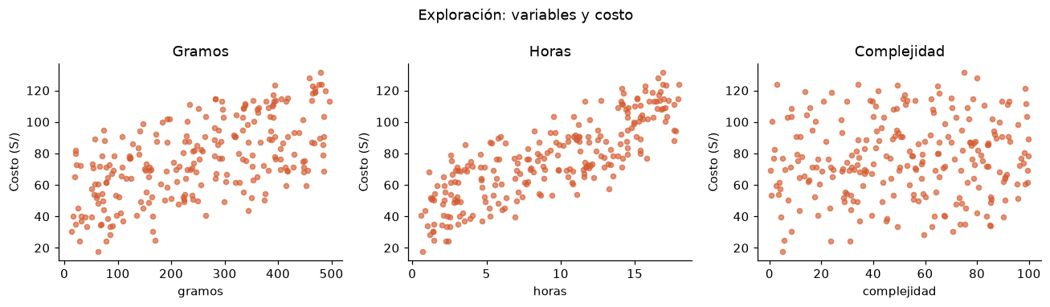

In [2]:
costos=np.loadtxt(root/'data'/'impresion_3d.csv',delimiter=',',skiprows=1)
nombres=['gramos','horas','complejidad','costo']
print('Dimensiones:',costos.shape,'Valores no finitos:',np.sum(~np.isfinite(costos)))
print('Variable          Mínimo    Máximo    Media     Desv. estándar')
for i,name in enumerate(nombres):
 print(f'{name:16} {costos[:,i].min():8.2f} {costos[:,i].max():9.2f} {costos[:,i].mean():8.2f} {costos[:,i].std():10.2f}')
assert costos.shape==(240,4) and np.isfinite(costos).all()
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for i,ax in enumerate(axes):
 ax.scatter(costos[:,i],costos[:,3],s=16,alpha=.65);ax.set(xlabel=nombres[i],ylabel='Costo (S/)',title=nombres[i].capitalize())
fig.suptitle('Exploración: variables y costo');fig.tight_layout();show(fig)

## 2. Entrenar una regresión múltiple
Separamos 180 filas para entrenamiento y 60 para prueba con semilla 42. Ajustamos exclusivamente sobre entrenamiento. Comparamos con una línea base que predice el promedio de entrenamiento.

MAE mide error absoluto medio en soles. R² mide variación explicada; puede ser negativo. Un R² alto en datos sintéticos lineales no demuestra validez comercial.

Entrenamiento/prueba: 180 60
MAE modelo: 2.159
MAE línea base: 20.378
R² prueba: 0.9868
MAE validación cruzada (solo entrenamiento): 1.925
Intercepto: 7.8855903710604025 Coeficientes: [0.09516881 3.8186714  0.17484448]


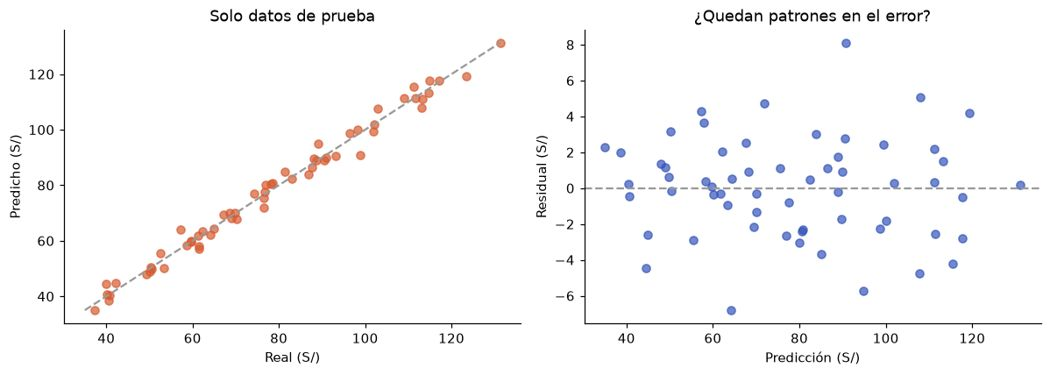

In [3]:
x,y=costos[:,:3],costos[:,3]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.25,random_state=42)
regresion=LinearRegression().fit(x_train,y_train)
y_pred=regresion.predict(x_test)
print('Entrenamiento/prueba:',len(x_train),len(x_test))
print('MAE modelo:',round(mean_absolute_error(y_test,y_pred),3))
print('MAE línea base:',round(mean_absolute_error(y_test,np.full_like(y_test,y_train.mean())),3))
print('R² prueba:',round(r2_score(y_test,y_pred),4))
cv=cross_val_score(LinearRegression(),x_train,y_train,cv=5,scoring='neg_mean_absolute_error')
print('MAE validación cruzada (solo entrenamiento):',round(-cv.mean(),3))
print('Intercepto:',regresion.intercept_,'Coeficientes:',regresion.coef_)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(y_test,y_pred,alpha=.7); lim=[min(y_test.min(),y_pred.min()),max(y_test.max(),y_pred.max())];axes[0].plot(lim,lim,'--',color='#999999');axes[0].set(xlabel='Real (S/)',ylabel='Predicho (S/)',title='Solo datos de prueba')
axes[1].scatter(y_pred,y_test-y_pred,alpha=.7,color='#3554bb');axes[1].axhline(0,color='#999999',linestyle='--');axes[1].set(xlabel='Predicción (S/)',ylabel='Residual (S/)',title='¿Quedan patrones en el error?')
fig.tight_layout();show(fig)

## 3. Explicar una predicción
El costo es la suma del intercepto y del aporte de cada variable. Esto permite justificar una estimación y detectar resultados extraños. El MAE global no es un intervalo de confianza individual.

In [4]:
pieza=np.array([150,4,40])
aportes=pieza*regresion.coef_
for name,value in zip(nombres[:3],aportes):print(name,round(value,2))
print('Base:',round(regresion.intercept_,2))
print('Total estimado:',round(regresion.predict([pieza])[0],2))

gramos 14.28
horas 15.27
complejidad 6.99
Base: 7.89
Total estimado: 44.43


## 4. Imágenes insertadas: analizar Digits
`data/digits.csv` incluye las 1797 imágenes reales del dataset Digits de scikit-learn: 64 intensidades entre 0 y 16 y una etiqueta del 0 al 9. No se descargan durante la ejecución. También hay diez PNG de muestra en `data/examples/`.

Comprobamos las clases y su distribución antes de separar los conjuntos.

Imágenes: 1797 Tamaño: (8, 8) Valores no finitos: 0
Registros por clase: {np.int64(0): np.int64(178), np.int64(1): np.int64(182), np.int64(2): np.int64(177), np.int64(3): np.int64(183), np.int64(4): np.int64(181), np.int64(5): np.int64(182), np.int64(6): np.int64(181), np.int64(7): np.int64(179), np.int64(8): np.int64(174), np.int64(9): np.int64(180)}


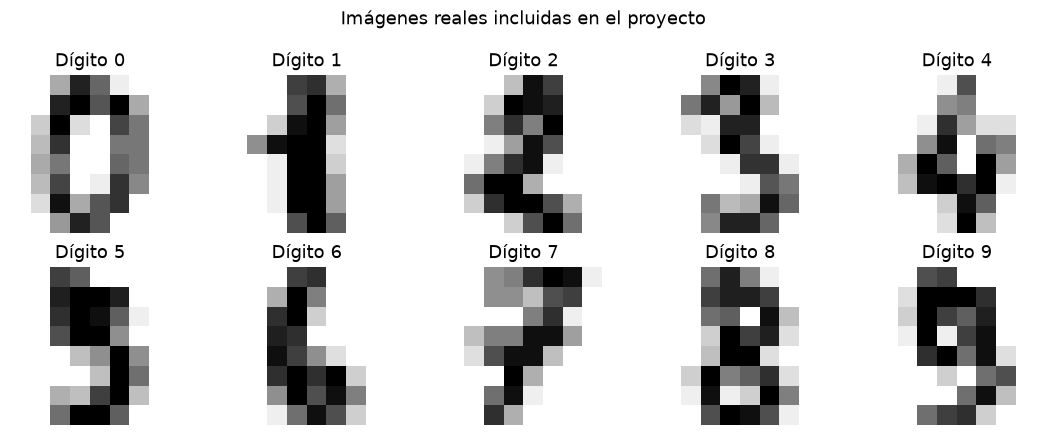

In [5]:
digits=np.loadtxt(root/'data'/'digits.csv',delimiter=',',skiprows=1)
imagenes=digits[:,:64].reshape(-1,8,8);etiquetas=digits[:,64].astype(int)
print('Imágenes:',len(imagenes),'Tamaño:',imagenes.shape[1:],'Valores no finitos:',np.sum(~np.isfinite(digits)))
print('Registros por clase:',dict(zip(*np.unique(etiquetas,return_counts=True))))
fig,axes=plt.subplots(2,5,figsize=(10,4))
for d,ax in enumerate(axes.flat):
 ax.imshow(imagenes[np.flatnonzero(etiquetas==d)[0]],cmap='gray_r');ax.set_title(f'Dígito {d}');ax.axis('off')
fig.suptitle('Imágenes reales incluidas en el proyecto');fig.tight_layout();show(fig)

## 5. Entrenar un modelo de imágenes de verdad
Preprocesamos con la misma función utilizada en el aplicativo: fondo, recorte y centrado a 8×8. Esta transformación no aprende parámetros del dataset. La estandarización sí aprende parámetros y se ajusta **dentro del pipeline solamente con entrenamiento**.

Separación estratificada 1347/450. Entrenamos regresión logística multiclase, no una red neuronal.

Entrenamiento/prueba: 1347 450
Exactitud en prueba: 0.9356
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        45
           1       0.86      0.93      0.90        46
           2       1.00      0.95      0.98        44
           3       0.98      1.00      0.99        46
           4       0.93      0.91      0.92        45
           5       0.96      0.93      0.95        46
           6       0.95      0.93      0.94        45
           7       0.92      0.98      0.95        45
           8       0.92      0.79      0.85        43
           9       0.88      0.93      0.90        45

    accuracy                           0.94       450
   macro avg       0.94      0.93      0.93       450
weighted avg       0.94      0.94      0.94       450



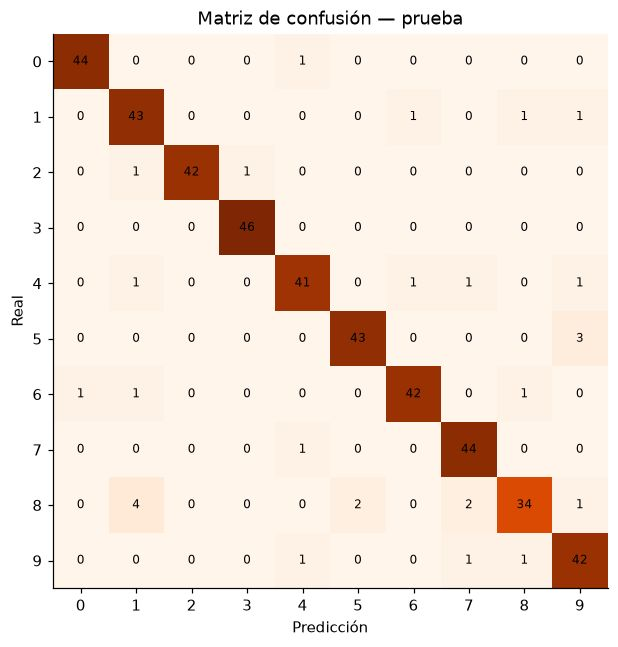

In [6]:
features=np.array([digit_features((im*255/16).astype(np.uint8)).ravel() for im in imagenes])
idx_train,idx_test=train_test_split(np.arange(len(imagenes)),test_size=.25,random_state=42,stratify=etiquetas)
clasificador=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1500,C=.1))
clasificador.fit(features[idx_train],etiquetas[idx_train])
pred=clasificador.predict(features[idx_test])
print('Entrenamiento/prueba:',len(idx_train),len(idx_test))
print('Exactitud en prueba:',round(accuracy_score(etiquetas[idx_test],pred),4))
print(classification_report(etiquetas[idx_test],pred,zero_division=0))
matriz=confusion_matrix(etiquetas[idx_test],pred)
fig,ax=plt.subplots(figsize=(7,6));ax.imshow(matriz,cmap='Oranges');ax.set(xticks=range(10),yticks=range(10),xlabel='Predicción',ylabel='Real',title='Matriz de confusión — prueba')
for i in range(10):
 for j in range(10):ax.text(j,i,str(matriz[i,j]),ha='center',va='center',fontsize=8)
fig.tight_layout();show(fig)

## 6. Experimento adicional: crear variaciones de las imágenes
Generamos pequeñas rotaciones de las imágenes **de entrenamiento**. Son imágenes aumentadas a partir de datos reales; no son fotografías nuevas ni imágenes de IA generativa. Entrenamos un segundo clasificador y lo evaluamos sobre la misma prueba intacta. La aplicación conserva el modelo base para que sus métricas sean reproducibles.

La mejora no se presupone: se mide y se informa aunque el resultado sea peor.

In [7]:
aumentadas=[];clases_aumentadas=[]
for idx in idx_train:
 im=cv2.resize((imagenes[idx]*255/16).astype(np.uint8),(64,64),interpolation=cv2.INTER_LINEAR)
 for angle in [-8,8]:
  transform=cv2.getRotationMatrix2D((31.5,31.5),angle,1)
  variant=cv2.warpAffine(im,transform,(64,64),borderValue=0)
  aumentadas.append(digit_features(variant).ravel());clases_aumentadas.append(etiquetas[idx])
train_aug=np.vstack((features[idx_train],np.array(aumentadas)))
labels_aug=np.concatenate((etiquetas[idx_train],clases_aumentadas))
modelo_aug=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1500,C=.1)).fit(train_aug,labels_aug)
print('Imágenes de entrenamiento base:',len(idx_train),'Variaciones generadas:',len(aumentadas))
print('Exactitud base:',round(accuracy_score(etiquetas[idx_test],pred),4))
print('Exactitud con aumento:',round(accuracy_score(etiquetas[idx_test],modelo_aug.predict(features[idx_test])),4))

Imágenes de entrenamiento base: 1347 Variaciones generadas: 2694
Exactitud base: 0.9356
Exactitud con aumento: 0.9333


## 7. OpenCV: ver más allá del color
La imagen de ejemplo viene incluida. Comparamos original, grises y bordes Canny. Explica qué cambia si el umbral sube o baja y qué tipo de información desaparece al convertir a grises.

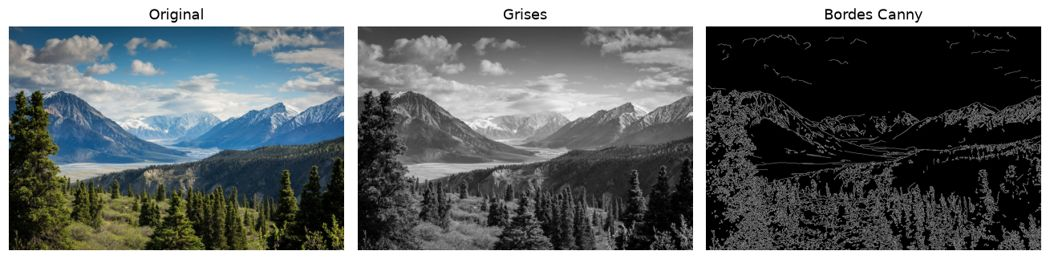

Luminosidad media: 100.26 Contraste: 58.86


In [8]:
paisaje=cv2.imread(str(root/'static'/'vision-sample.jpg'))
gris=cv2.cvtColor(paisaje,cv2.COLOR_BGR2GRAY)
bordes=cv2.Canny(cv2.GaussianBlur(gris,(5,5),0),50,125)
fig,axes=plt.subplots(1,3,figsize=(12,4))
for ax,im,title in zip(axes,[cv2.cvtColor(paisaje,cv2.COLOR_BGR2RGB),gris,bordes],['Original','Grises','Bordes Canny']):
 ax.imshow(im,cmap='gray');ax.set_title(title);ax.axis('off')
fig.tight_layout();show(fig)
print('Luminosidad media:',round(float(gris.mean()),2),'Contraste:',round(float(gris.std()),2))

## 8. Objetos: integrar una red neuronal preentrenada
MobileNetV2 fue entrenada por sus autores sobre ImageNet. Las 1000 etiquetas están incluidas en `models/`. Los pesos ONNX se descargan de la fuente oficial al primer uso y se verifican con SHA-256; `models/manifest.json` registra su origen y huella. Aquí hacemos inferencia con OpenCV DNN, **sin entrenar otra vez ImageNet**.

Preprocesado documentado: lado corto a 256, recorte central de 224×224, RGB en [0,1], media [0.485,0.456,0.406], desviación [0.229,0.224,0.225], softmax y top-5. Es clasificación de un contenido principal, no detección múltiple. Hay más de 100 categorías de objetos, pero no existe una garantía de reconocer cualquier objeto cotidiano.

Categorías: 1000
Ejemplos de etiquetas: [{'id': 418, 'name': 'Lapicero / bolígrafo', 'original': 'ballpoint', 'group': 'Objetos y alimentos'}, {'id': 504, 'name': 'Taza', 'original': 'coffee mug', 'group': 'Objetos y alimentos'}, {'id': 508, 'name': 'Teclado de computadora', 'original': 'computer keyboard', 'group': 'Objetos y alimentos'}, {'id': 620, 'name': 'Laptop / portátil', 'original': 'laptop', 'group': 'Objetos y alimentos'}, {'id': 710, 'name': 'Tajador / sacapuntas', 'original': 'pencil sharpener', 'group': 'Objetos y alimentos'}, {'id': 767, 'name': 'Borrador', 'original': 'rubber eraser', 'group': 'Objetos y alimentos'}]


laptop : [('notebook', 62.15), ('modem', 9.51), ('desktop computer', 5.7), ('computer keyboard', 5.58), ('screen', 3.1)] segundos: 0.223
banana : [('banana', 99.93), ('lemon', 0.01), ('custard apple', 0.01), ('zucchini', 0.01), ('bell pepper', 0.01)] segundos: 0.06
coffee : [('face powder', 34.74), ('espresso', 16.63), ('bottlecap', 7.74), ('combination lock', 5.1), ('typewriter keyboard', 5.0)] segundos: 0.062


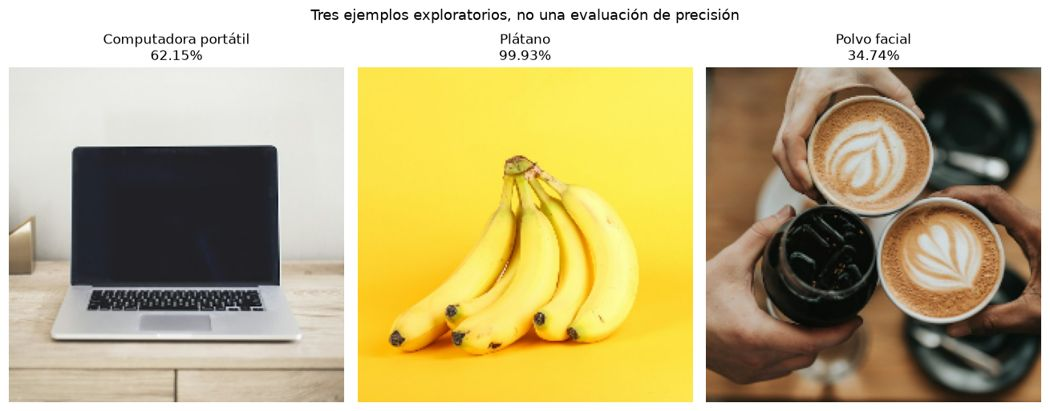

In [9]:
clases=catalog()
print('Categorías:',len(clases))
print('Ejemplos de etiquetas:',[c for c in clases if c['original'] in ['ballpoint','laptop','computer keyboard','coffee mug','rubber eraser','pencil sharpener']])
fig,axes=plt.subplots(1,3,figsize=(12,5))
for ax,name in zip(axes,['laptop','banana','coffee']):
 im=cv2.imread(str(root/'static'/f'object-{name}.jpg'))
 start=time.perf_counter();top,crop=classify_object(im);elapsed=time.perf_counter()-start
 ax.imshow(cv2.cvtColor(crop,cv2.COLOR_BGR2RGB));ax.axis('off');ax.set_title(top[0]['name']+'\n'+str(top[0]['probability'])+'%',fontsize=11)
 print(name,':',[(p['original'],p['probability']) for p in top],'segundos:',round(elapsed,3))
fig.suptitle('Tres ejemplos exploratorios, no una evaluación de precisión');fig.tight_layout();show(fig)

## 9. Analizar errores y límites
- Una foto de café puede confundirse por el encuadre central; revisar el top-5 ayuda a interpretar la incertidumbre.
- No se calcula una precisión propia de ImageNet sobre estas tres fotos: faltan un conjunto de prueba representativo y etiquetas independientes.
- Las probabilidades no garantizan un acierto. Objetos fuera del catálogo igualmente reciben una clase conocida.
- «Notebook» en ImageNet representa una computadora portátil; los colores y las hojas de papel no son categorías generales independientes.
- Para reconocer varios objetos a la vez se necesitaría un detector y otro conjunto de clases. Este proyecto no anuncia cajas ni conteos que no produce.
- No se infieren emociones ni estados mentales a partir de rostros.

## 10. Del análisis al sistema web
El navegador proporciona fotos o fotogramas autorizados. Flask valida tamaño y tipo. OpenCV realiza el preprocesado y la inferencia. La interfaz explica el resultado y permite guardarlo en una bitácora local. Git versiona el proyecto y Render publica frontend y backend.

In [10]:
from app import app
cliente=app.test_client()
print('Salud:',cliente.get('/health').json)
print('Predicción:',cliente.post('/api/predict',json={'grams':150,'hours':4,'complexity':40}).json)
print('Catálogo API:',cliente.get('/api/objects/catalog').json['total'])

Salud: {'application': 'Nexo Lab', 'status': 'ok', 'version': '2.0.0'}
Predicción: {'base': 7.8856, 'contributions': [14.28, 15.27, 6.99], 'mae': 2.16, 'note': 'Estimación académica con datos sintéticos. No constituye una cotización comercial.', 'prediction': 44.43}
Catálogo API: 1000


## Fuentes y preguntas para sustentar
- Datasets Digits: scikit-learn, https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html
- Pesos MobileNetV2: ONNX Model Zoo, licencia Apache 2.0, https://github.com/onnx/models/tree/main/validated/vision/classification/mobilenet
- OpenCV: https://docs.opencv.org/4.x/
- Fuentes y licencia de las fotografías en README.md. Logo y fondo generados para este proyecto; **no son imágenes de entrenamiento del clasificador de objetos**.

**Preguntas:** ¿Qué cambia entre entrenamiento e inferencia? ¿Cómo evitamos fuga de datos? ¿Qué significan MAE, R² y exactitud? ¿Por qué una probabilidad alta puede fallar? ¿Cómo afectó el aumento de imágenes? ¿Qué mejoras exigiría una evaluación con objetos del aula?